
# PHASE 5: EXPLAINABLE AI (XAI)
## Step 5.1 — Setup & Data Loading


In [8]:

# ============================================================
# PHASE 5 — STEP 5.1: SETUP AND DATA LOADING
# Smart Cybersecurity ML — Explainable AI
# ============================================================

from pathlib import Path
import warnings
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    precision_recall_fscore_support
)

warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["font.size"] = 10

# Project paths
cwd = Path.cwd()
project_root = cwd.parent if cwd.name.lower() == "notebooks" else cwd

processed_dir = project_root / "data" / "processed"
models_dir = project_root / "models"
results_dir = project_root / "results" / "phase5"

results_dir.mkdir(parents=True, exist_ok=True)

# Check required files
required_files = [
    processed_dir / "X_train_encoded.csv",
    processed_dir / "X_test_encoded.csv",
    processed_dir / "X_test_scaled.npy",
    processed_dir / "y_test_encoded.npy",
    processed_dir / "target_encoder.pkl",
    processed_dir / "scaler.pkl",
    models_dir / "final_xgboost_model.pkl"
]

missing_files = [str(p) for p in required_files if not p.exists()]

if missing_files:
    raise FileNotFoundError(
        "Required files missing:\n" + "\n".join(missing_files)
    )

# Load data and model
X_train = pd.read_csv(processed_dir / "X_train_encoded.csv")
X_test = pd.read_csv(processed_dir / "X_test_encoded.csv")

X_test_scaled = np.load(processed_dir / "X_test_scaled.npy")
y_test = np.load(processed_dir / "y_test_encoded.npy")

target_encoder = joblib.load(processed_dir / "target_encoder.pkl")
scaler = joblib.load(processed_dir / "scaler.pkl")
xgb_model = joblib.load(models_dir / "final_xgboost_model.pkl")

class_names = target_encoder.classes_.tolist()
num_classes = len(class_names)

# Verify model and data dimensions
print("=" * 65)
print("PHASE 5: EXPLAINABLE AI — INTRUSION DETECTION")
print("=" * 65)

print("\nProject root:", project_root)
print("Model:", type(xgb_model).__name__)
print("Training feature table:", X_train.shape)
print("Test encoded table:", X_test.shape)
print("Test scaled data:", X_test_scaled.shape)
print("Test labels:", y_test.shape)
print("Attack classes:", num_classes)
print("Feature names available:", X_train.columns.is_unique)
print("Results directory:", results_dir)

# Ensure the test matrix matches the model input
if X_test_scaled.shape[1] != X_train.shape[1]:
    raise ValueError(
        "Feature-count mismatch between test matrix and feature table."
    )

if len(y_test) != len(X_test_scaled):
    raise ValueError("Test sample count does not match test labels.")

print("\nSTEP 5.1 COMPLETED: data and model loaded successfully.")


PHASE 5: EXPLAINABLE AI — INTRUSION DETECTION

Project root: d:\smart-cybersecurity-ml
Model: XGBClassifier
Training feature table: (118783, 41)
Test encoded table: (29696, 41)
Test scaled data: (29696, 41)
Test labels: (29696,)
Attack classes: 28
Feature names available: True
Results directory: d:\smart-cybersecurity-ml\results\phase5

STEP 5.1 COMPLETED: data and model loaded successfully.



## Step 5.2 — Baseline Model Performance


In [38]:

# ============================================================
# PHASE 5 — STEP 5.2: BASELINE MODEL PERFORMANCE
# ============================================================

print("=" * 65)
print("STEP 5.2: BASELINE MODEL PERFORMANCE")
print("=" * 65)

# Generate predictions
y_pred = xgb_model.predict(X_test_scaled)

# Calculate overall metrics
acc = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)
weighted_f1 = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

print(f"\nAccuracy    : {acc:.6f}")
print(f"Macro F1    : {macro_f1:.6f}")
print(f"Weighted F1 : {weighted_f1:.6f}")

# Calculate per-class metrics
precision, recall, f1, support = precision_recall_fscore_support(
    y_test,
    y_pred,
    labels=np.arange(num_classes),
    average=None,
    zero_division=0
)

per_class_df = pd.DataFrame({
    "Attack": class_names,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "Support": support
}).sort_values("F1", ascending=False)

print("\nTOP 15 CLASSES BY F1")
print(per_class_df.head(15).to_string(index=False))

print("\nWEAKEST 10 CLASSES BY F1")
print(
    per_class_df.tail(10)
    .sort_values("F1")
    .to_string(index=False)
)

# Save results
performance_path = results_dir / "phase5_per_class_performance.csv"
per_class_df.to_csv(performance_path, index=False)

print("\nSaved:", performance_path)
print("STEP 5.2 COMPLETED SUCCESSFULLY")


STEP 5.2: BASELINE MODEL PERFORMANCE

Accuracy    : 0.997542
Macro F1    : 0.836976
Weighted F1 : 0.997449

TOP 15 CLASSES BY F1
      Attack  Precision   Recall       F1  Support
     apache2   1.000000 1.000000 1.000000       46
        back   1.000000 1.000000 1.000000      237
        imap   1.000000 1.000000 1.000000        2
  httptunnel   1.000000 1.000000 1.000000        8
    mailbomb   1.000000 1.000000 1.000000       19
   snmpguess   1.000000 1.000000 1.000000       20
     neptune   0.999791 0.999896 0.999843     9574
       smurf   1.000000 0.998430 0.999214      637
      normal   0.998283 0.998855 0.998569    15718
   portsweep   1.000000 0.996970 0.998483      660
     ipsweep   0.995116 0.998775 0.996942      816
 warezclient   1.000000 0.989950 0.994949      199
guess_passwd   1.000000 0.989247 0.994595       93
    teardrop   0.994924 0.984925 0.989899      199
        nmap   0.997015 0.982353 0.989630      340

WEAKEST 10 CLASSES BY F1
         Attack  Precision   


## Step 5.3 — XGBoost Feature Importance Analysis
### Gain, Weight, Cover and Total Gain


STEP 5.3: XGBOOST FEATURE IMPORTANCE
Computed weight; saved: phase5_feature_importance_weight.csv
Computed gain; saved: phase5_feature_importance_gain.csv
Computed cover; saved: phase5_feature_importance_cover.csv
Computed total_gain; saved: phase5_feature_importance_total_gain.csv

TOP 20 FEATURES BY GAIN
Feature Feature_Name  Importance
     f6           f6  698.815613
     f8           f8  587.063843
    f28          f28  465.742889
     f7           f7  365.454193
    f10          f10  349.490631
    f13          f13  264.051270
    f17          f17  241.546234
    f25          f25  138.501541
    f15          f15  124.001602
    f18          f18  112.961617
     f1           f1   99.021538
     f4           f4   97.633965
    f29          f29   88.581696
     f3           f3   88.310638
    f36          f36   69.205292
    f21          f21   53.812222
     f0           f0   48.689888
     f5           f5   38.283066
    f40          f40   37.828346
     f9           f9   36.680840

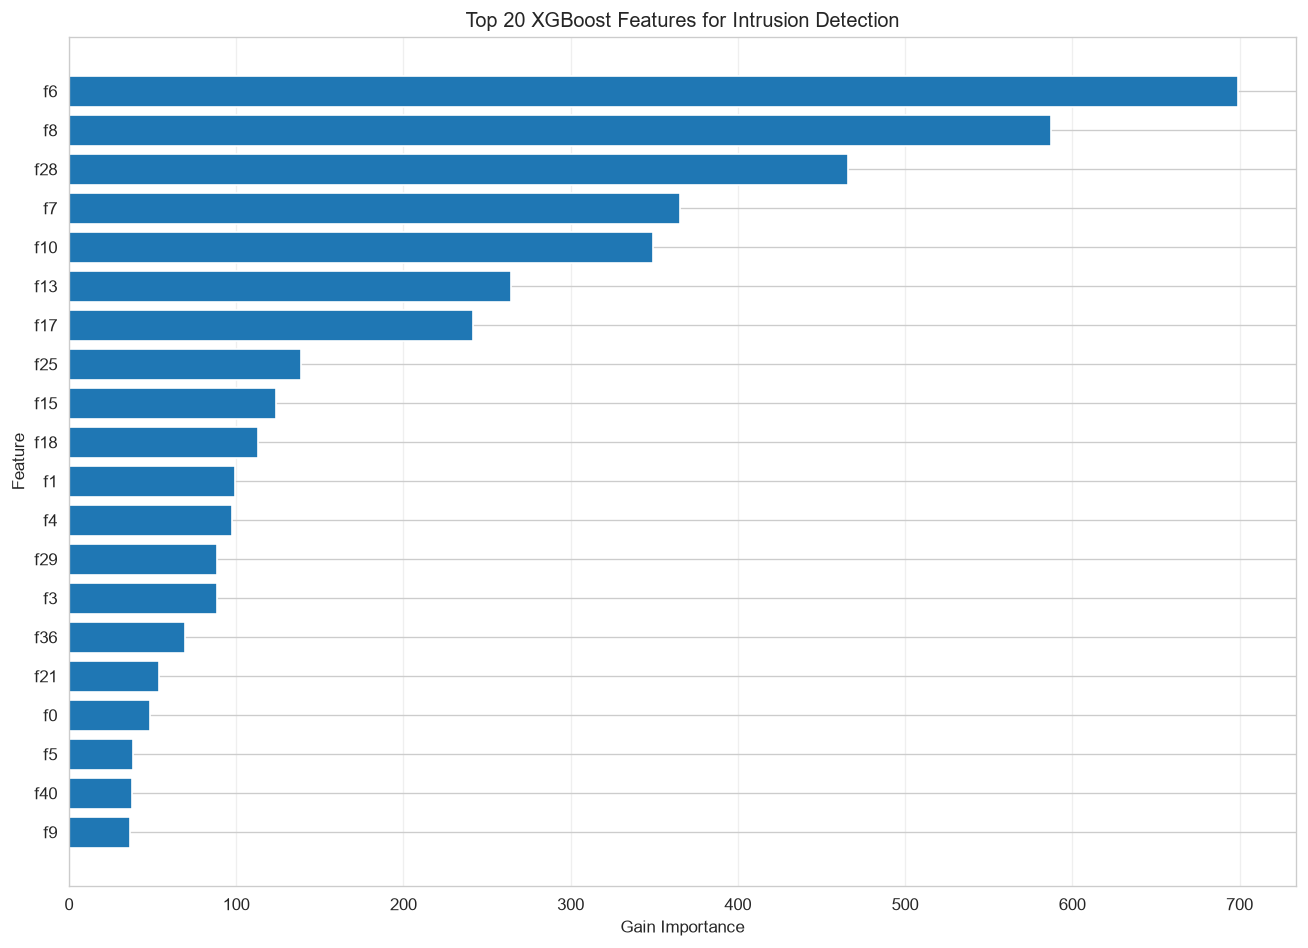


Saved: D:\smart-cybersecurity-ml\results\phase5\phase5_feature_importance.csv
Saved: D:\smart-cybersecurity-ml\results\phase5\phase5_feature_importance_top20.png
STEP 5.3 COMPLETED SUCCESSFULLY


In [50]:

# ============================================================
# PHASE 5 — STEP 5.3: XGBOOST FEATURE IMPORTANCE
# ============================================================

print("=" * 65)
print("STEP 5.3: XGBOOST FEATURE IMPORTANCE")
print("=" * 65)

booster = xgb_model.get_booster()

importance_types = ["weight", "gain", "cover", "total_gain"]
importance_dfs = {}

# Create feature names matching the model's 41 input columns
feature_count = X_train.shape[1]
model_feature_names = [f"f{i}" for i in range(feature_count)]

for imp_type in importance_types:
    raw_importance = booster.get_score(importance_type=imp_type)

    # Support both f0/f1-style keys and named model features
    values = []
    for i, name in enumerate(model_feature_names):
        value = raw_importance.get(name, 0.0)

        if name not in raw_importance and X_train.shape[1] == feature_count:
            # Some models store feature names differently.
            value = raw_importance.get(str(i), 0.0)

        values.append(value)

    imp_df = pd.DataFrame({
        "Feature": model_feature_names,
        "Feature_Name": model_feature_names,
        "Importance": values
    }).sort_values("Importance", ascending=False)

    importance_dfs[imp_type] = imp_df

    output_path = results_dir / f"phase5_feature_importance_{imp_type}.csv"
    imp_df.to_csv(output_path, index=False)

    print(f"Computed {imp_type}; saved: {output_path.name}")

# Gain is the primary importance measure
primary_importance = importance_dfs["gain"].copy()

print("\nTOP 20 FEATURES BY GAIN")
print(primary_importance.head(20).to_string(index=False))

# Save primary feature importance
primary_path = results_dir / "phase5_feature_importance.csv"
primary_importance.to_csv(primary_path, index=False)

# Plot top 20 features
top20 = primary_importance.head(20).sort_values("Importance")

fig, ax = plt.subplots(figsize=(11, 8))
ax.barh(top20["Feature_Name"], top20["Importance"])
ax.set_xlabel("Gain Importance")
ax.set_ylabel("Feature")
ax.set_title("Top 20 XGBoost Features for Intrusion Detection")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

plot_path = results_dir / "phase5_feature_importance_top20.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nSaved:", primary_path)
print("Saved:", plot_path)
print("STEP 5.3 COMPLETED SUCCESSFULLY")


Step 5.4: SHAP Explainable AI

## Step 5.4.1: SHAP Library Verification

**Objective:** Verify that SHAP can be imported successfully before performing model explanations.

In [119]:

# ============================================================
# PHASE 5 — STEP 5.4.1: SHAP LIBRARY VERIFICATION
# ============================================================

try:
    import shap

    print("SHAP version:", shap.__version__)
    print("SHAP imported successfully!")
    print("Ready for Step 5.4.2: Model explanation.")

except Exception as e:
    print("SHAP import failed.")
    print("Error type:", type(e).__name__)
    print("Error details:", str(e)[:1000])
    print("\nDo not bypass Windows security. We will use a safe alternative if needed.")


SHAP version: 0.53.0
SHAP imported successfully!
Ready for Step 5.4.2: Model explanation.


Step 5.4.2 — SHAP Global Explanation

In [77]:
# ============================================================
# PHASE 5 — STEP 5.4.2: SHAP GLOBAL EXPLANATION
# ============================================================

import shap
import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("STEP 5.4.2: SHAP GLOBAL EXPLANATION")
print("=" * 70)

# 1. Verify required variables
required_vars = [
    "xgb_model", "X_test_scaled",
    "X_train", "y_test", "results_dir"
]

missing_vars = [
    name for name in required_vars
    if name not in globals()
]

if missing_vars:
    raise NameError(
        f"Missing variables: {missing_vars}. "
        "Run the earlier Phase 5 setup cells first."
    )

# 2. Use a manageable test sample
sample_size = min(200, len(X_test_scaled))

np.random.seed(42)
sample_indices = np.random.choice(
    len(X_test_scaled),
    size=sample_size,
    replace=False
)

X_sample = X_test_scaled[sample_indices]
y_sample = y_test[sample_indices]

print(f"SHAP sample size: {sample_size}")
print(f"Feature count: {X_train.shape[1]}")

# 3. Initialize TreeExplainer
print("\nInitializing SHAP TreeExplainer...")

explainer = shap.TreeExplainer(xgb_model)

# 4. Calculate SHAP values
print("Calculating SHAP values...")

shap_values = explainer.shap_values(X_sample)

print("SHAP values calculated successfully.")

if isinstance(shap_values, list):
    print("SHAP format: list of class-specific arrays")
    print("Number of class arrays:", len(shap_values))
    print("First class array shape:", shap_values[0].shape)
else:
    print("SHAP format:", type(shap_values).__name__)
    print("SHAP shape:", np.asarray(shap_values).shape)

print("\nStep 5.4.2 completed.")

STEP 5.4.2: SHAP GLOBAL EXPLANATION
SHAP sample size: 200
Feature count: 41

Initializing SHAP TreeExplainer...
Calculating SHAP values...
SHAP values calculated successfully.
SHAP format: ndarray
SHAP shape: (200, 41, 28)

Step 5.4.2 completed.


Step 5.4.3 — SHAP Analysis and Visualization

In [83]:
# ============================================================
# PHASE 5 — STEP 5.4.3: VERIFY SHAP OUTPUTS
# ============================================================

print("Explainer available:", "explainer" in globals())
print("SHAP values available:", "shap_values" in globals())

if "shap_values" in globals():
    print("SHAP values shape:", np.asarray(shap_values).shape)

if "X_sample" in globals():
    print("Sample data shape:", np.asarray(X_sample).shape)

Explainer available: True
SHAP values available: True
SHAP values shape: (200, 41, 28)
Sample data shape: (200, 41)


TEP 5.4.3: SHAP GLOBAL ANALYSIS & VISUALIZATION

STEP 5.4.3: SHAP GLOBAL ANALYSIS & VISUALIZATION

Top 15 features by mean absolute SHAP value:
                    Feature  Mean_Absolute_SHAP
                  src_bytes            0.832350
                    service            0.560725
         dst_host_srv_count            0.415512
                  dst_bytes            0.397920
             dst_host_count            0.342627
              protocol_type            0.324611
dst_host_same_src_port_rate            0.285713
     dst_host_same_srv_rate            0.263598
     dst_host_diff_srv_rate            0.255856
       dst_host_rerror_rate            0.252415
                      count            0.239759
                       flag            0.166546
                  srv_count            0.159621
   dst_host_srv_serror_rate            0.151670
dst_host_srv_diff_host_rate            0.142265

Saved: D:\smart-cybersecurity-ml\results\phase5\phase5_shap_global_importance.csv


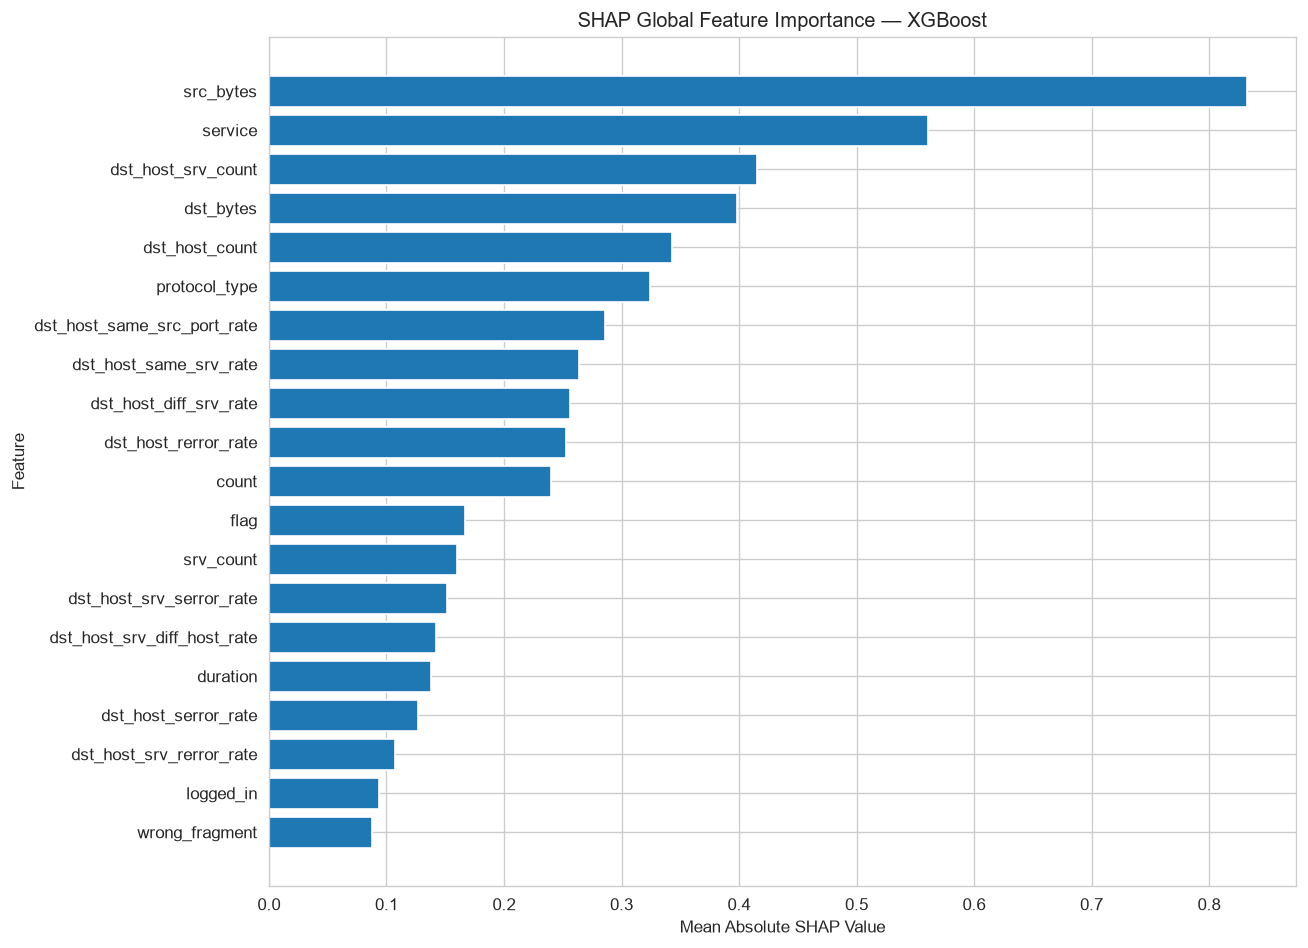

Saved: D:\smart-cybersecurity-ml\results\phase5\phase5_shap_global_importance.png

STEP 5.4.3 GLOBAL ANALYSIS COMPLETED.


In [101]:

# ============================================================
# PHASE 5 — STEP 5.4.3: SHAP GLOBAL ANALYSIS & VISUALIZATION
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("STEP 5.4.3: SHAP GLOBAL ANALYSIS & VISUALIZATION")
print("=" * 70)

# 1. Verify existing SHAP outputs
assert "shap_values" in globals(), "Run Step 5.4.2 first."
assert "X_sample" in globals(), "X_sample is missing."

values = np.asarray(shap_values)
sample_data = np.asarray(X_sample)

# Expected multiclass format: samples x features x classes
assert values.ndim == 3, f"Unexpected SHAP shape: {values.shape}"
assert values.shape[0] == sample_data.shape[0]
assert values.shape[1] == sample_data.shape[1]

# 2. Recover feature names
if (
    "X_test_encoded" in globals()
    and hasattr(X_test_encoded, "columns")
    and len(X_test_encoded.columns) == values.shape[1]
):
    feature_names = list(X_test_encoded.columns)
elif (
    "X_train" in globals()
    and hasattr(X_train, "columns")
    and len(X_train.columns) == values.shape[1]
):
    feature_names = list(X_train.columns)
else:
    feature_names = [f"feature_{i}" for i in range(values.shape[1])]

# 3. Calculate global importance across samples and classes
global_importance = np.mean(np.abs(values), axis=(0, 2))

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": global_importance
}).sort_values("Mean_Absolute_SHAP", ascending=False)

# 4. Prepare results directory
if "results_dir" in globals():
    output_dir = results_dir
else:
    output_dir = os.path.abspath(
        os.path.join("results", "phase5")
    )

os.makedirs(output_dir, exist_ok=True)

# 5. Save full global importance table
csv_path = os.path.join(
    output_dir, "phase5_shap_global_importance.csv"
)
importance_df.to_csv(csv_path, index=False)

print("\nTop 15 features by mean absolute SHAP value:")
print(importance_df.head(15).to_string(index=False))

print(f"\nSaved: {csv_path}")

# 6. Plot top 20 features
top_n = min(20, len(importance_df))
plot_df = importance_df.head(top_n).sort_values(
    "Mean_Absolute_SHAP", ascending=True
)

plt.figure(figsize=(11, 8))
plt.barh(
    plot_df["Feature"],
    plot_df["Mean_Absolute_SHAP"]
)
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("SHAP Global Feature Importance — XGBoost")
plt.tight_layout()

plot_path = os.path.join(
    output_dir, "phase5_shap_global_importance.png"
)
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print(f"Saved: {plot_path}")
print("\nSTEP 5.4.3 GLOBAL ANALYSIS COMPLETED.")


## Step 5.5.1: LIME Library Verification

**Objective:** Check whether LIME is available for explaining individual XGBoost predictions.

In [ ]:

# ============================================================
# PHASE 5 — STEP 5.5.1: LIME LIBRARY VERIFICATION
# ============================================================

try:
    from lime.lime_tabular import LimeTabularExplainer

    print("LIME imported successfully!")
    print("Ready for individual prediction explanations.")

except ImportError as e:
    print("LIME is not available in this environment.")
    print("Error:", str(e))


LIME imported successfully!
Ready for individual prediction explanations.


5.5.2 — LIME explainer configure karna

In [ ]:

# ============================================================
# PHASE 5 — STEP 5.5.2: CONFIGURE LIME EXPLAINER
# ============================================================

from lime.lime_tabular import LimeTabularExplainer
import numpy as np
import pandas as pd

# Use generic names because the model has 41 encoded input features
feature_count = X_train.shape[1]
lime_feature_names = [f"feature_{i}" for i in range(feature_count)]

# Configure LIME for multiclass classification
lime_explainer = LimeTabularExplainer(
    training_data=np.asarray(X_train, dtype=float),
    feature_names=lime_feature_names,
    class_names=[str(name) for name in class_names],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

# Select one test record for explanation
sample_index = 0
sample_record = np.asarray(X_test_scaled[sample_index], dtype=float)

print("LIME explainer configured successfully!")
print("Training data shape:", X_train.shape)
print("Test record shape:", sample_record.shape)
print("Number of classes:", len(class_names))
print("Selected test record index:", sample_index)
print("STEP 5.4.3 COMPLETED SUCCESSFULLY")


LIME explainer configured successfully!
Training data shape: (118783, 41)
Test record shape: (41,)
Number of classes: 28
Selected test record index: 0
STEP 5.4.3 COMPLETED SUCCESSFULLY


## Step 5.5.3: Explain an Individual Prediction Using LIME

**Objective:** Explain one XGBoost prediction and visualize the features influencing the selected prediction.

LIME INDIVIDUAL PREDICTION EXPLANATION
Test record index : 0
Actual class      : normal
Predicted class   : normal
Prediction confidence: 99.9987%

TOP FEATURES IN LIME EXPLANATION
------------------------------------------------------------
feature_4 <= 0.00                      0.25561
feature_9 <= 0.00                      0.15431
feature_11 > 1.00                      0.12578
feature_33 > 1.00                      0.12578
feature_15 <= 0.00                     0.10973
feature_12 <= 0.00                     0.09043
feature_38 <= 0.00                     0.06837
feature_26 <= 0.00                     0.06121
feature_0 <= 0.00                     -0.05961
feature_13 <= 0.00                    -0.04665
feature_27 <= 0.00                     0.04541
feature_32 <= 11.00                    0.03392
feature_37 <= 0.00                    -0.03006
0.10 < feature_28 <= 1.00              0.01862
feature_16 <= 0.00                    -0.01237


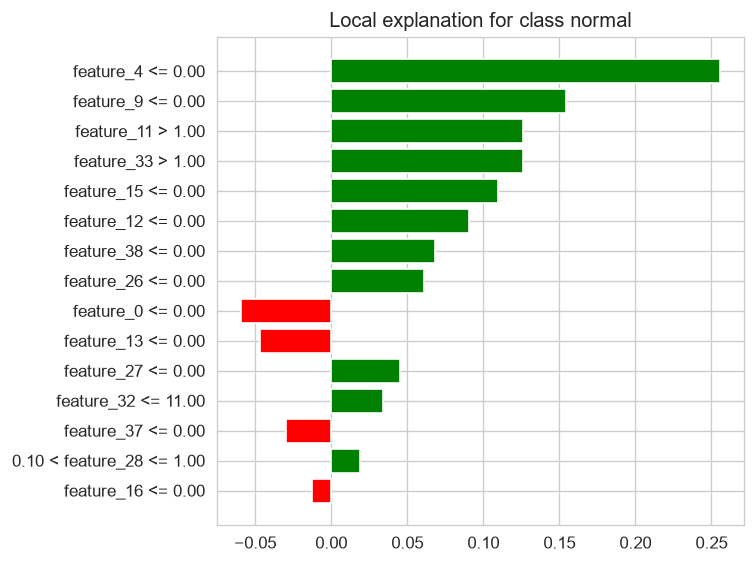


Saved LIME explanation graph: D:\smart-cybersecurity-ml\results\phase5\phase5_lime_individual_explanation.png
STEP 5.4.4 COMPLETED SUCCESSFULLY


In [ ]:

# ============================================================
# PHASE 5 — STEP 5.5.3: LIME INDIVIDUAL EXPLANATION
# ============================================================

# Generate explanation for the selected test record
lime_explanation = lime_explainer.explain_instance(
    data_row=sample_record,
    predict_fn=xgb_model.predict_proba,
    num_features=15,
    top_labels=1,
    num_samples=2000
)

# Get model prediction and predicted class
sample_probabilities = xgb_model.predict_proba(
    sample_record.reshape(1, -1)
)[0]

predicted_class_index = int(np.argmax(sample_probabilities))
predicted_class_name = class_names[predicted_class_index]
predicted_confidence = float(sample_probabilities[predicted_class_index])

# Get actual class, if available
actual_class_index = int(y_test[sample_index])
actual_class_name = class_names[actual_class_index]

print("=" * 60)
print("LIME INDIVIDUAL PREDICTION EXPLANATION")
print("=" * 60)
print("Test record index :", sample_index)
print("Actual class      :", actual_class_name)
print("Predicted class   :", predicted_class_name)
print("Prediction confidence:", f"{predicted_confidence:.4%}")

print("\nTOP FEATURES IN LIME EXPLANATION")
print("-" * 60)

explanation_label = predicted_class_index
for feature, weight in lime_explanation.as_list(label=explanation_label):
    print(f"{feature:<35} {weight:>10.5f}")

# Display the LIME explanation graph
fig = lime_explanation.as_pyplot_figure(label=explanation_label)
fig.tight_layout()

lime_plot_path = results_dir / "phase5_lime_individual_explanation.png"
fig.savefig(lime_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nSaved LIME explanation graph:", lime_plot_path)
print("STEP 5.4.4 COMPLETED SUCCESSFULLY")


## Step 5.5.4: Save LIME Explanation Results

**Objective:** Export the individual prediction, confidence, actual label, and LIME feature weights to a CSV file.

In [ ]:

# ============================================================
# PHASE 5 — STEP 5.5.4: SAVE LIME EXPLANATION
# ============================================================

lime_rows = lime_explanation.as_list(label=predicted_class_index)

lime_results_df = pd.DataFrame(
    lime_rows,
    columns=["Feature_Condition", "LIME_Weight"]
)

lime_results_df.insert(0, "Sample_Index", sample_index)
lime_results_df["Actual_Class"] = actual_class_name
lime_results_df["Predicted_Class"] = predicted_class_name
lime_results_df["Prediction_Confidence"] = predicted_confidence

lime_csv_path = results_dir / "phase5_lime_individual_explanation.csv"
lime_results_df.to_csv(lime_csv_path, index=False)

print("LIME explanation saved successfully!")
print("CSV path:", lime_csv_path)
print("\nSaved explanation preview:")
print(lime_results_df.head(10).to_string(index=False))
print("\nSTEP 5.4.5 COMPLETED SUCCESSFULLY")


LIME explanation saved successfully!
CSV path: D:\smart-cybersecurity-ml\results\phase5\phase5_lime_individual_explanation.csv

Saved explanation preview:
 Sample_Index  Feature_Condition  LIME_Weight Actual_Class Predicted_Class  Prediction_Confidence
            0  feature_4 <= 0.00     0.255613       normal          normal               0.999987
            0  feature_9 <= 0.00     0.154305       normal          normal               0.999987
            0  feature_11 > 1.00     0.125781       normal          normal               0.999987
            0  feature_33 > 1.00     0.125781       normal          normal               0.999987
            0 feature_15 <= 0.00     0.109734       normal          normal               0.999987
            0 feature_12 <= 0.00     0.090432       normal          normal               0.999987
            0 feature_38 <= 0.00     0.068373       normal          normal               0.999987
            0 feature_26 <= 0.00     0.061209       normal   

## Step 5.6: Attack-Class Behaviour Analysis

**Objective:** Analyze per-class precision, recall, F1-score, support, and misclassified records to identify attack classes that need further investigation.



In [ ]:

# ============================================================
# PHASE 5 — STEP 5.5.1: ATTACK-CLASS BEHAVIOUR ANALYSIS
# ============================================================

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)

# Predict all test records
y_pred = xgb_model.predict(X_test_scaled)
y_pred = np.asarray(y_pred).reshape(-1).astype(int)
y_true = np.asarray(y_test).reshape(-1).astype(int)

# Per-class metrics
precision, recall, f1, support = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    zero_division=0
)

class_analysis_df = pd.DataFrame({
    "Attack": class_names,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "Support": support
})

# Lowest F1 scores help identify classes needing investigation
class_analysis_df = class_analysis_df.sort_values(
    ["F1", "Support"],
    ascending=[True, True]
).reset_index(drop=True)

class_csv_path = results_dir / "phase5_attack_class_analysis.csv"
class_analysis_df.to_csv(class_csv_path, index=False)

print("=" * 65)
print("ATTACK-CLASS BEHAVIOUR ANALYSIS")
print("=" * 65)

print("\n10 CLASSES WITH LOWEST F1")
print(class_analysis_df.head(10).to_string(index=False))

print("\nCLASS ANALYSIS SAVED TO:")
print(class_csv_path)

# Save misclassified examples
misclassified_mask = y_true != y_pred
misclassified_indices = np.flatnonzero(misclassified_mask)

misclassified_df = pd.DataFrame({
    "Test_Index": misclassified_indices,
    "Actual_Class": [class_names[i] for i in y_true[misclassified_indices]],
    "Predicted_Class": [class_names[i] for i in y_pred[misclassified_indices]]
})

misclassified_csv_path = results_dir / "phase5_misclassified_records.csv"
misclassified_df.to_csv(misclassified_csv_path, index=False)

print("\nTotal test records:", len(y_true))
print("Misclassified records:", len(misclassified_indices))
print("Misclassification rate:", f"{misclassified_mask.mean():.4%}")
print("Misclassified records saved to:", misclassified_csv_path)

print("\nSTEP 5.5.2 COMPLETED SUCCESSFULLY")


ATTACK-CLASS BEHAVIOUR ANALYSIS

10 CLASSES WITH LOWEST F1
         Attack  Precision   Recall       F1  Support
      ftp_write   0.000000 0.000000 0.000000        2
       multihop   0.000000 0.000000 0.000000        3
        rootkit   0.000000 0.000000 0.000000        3
          saint   0.611111 0.578947 0.594595       19
     loadmodule   1.000000 0.500000 0.666667        2
  snmpgetattack   0.636364 0.777778 0.700000        9
           land   0.571429 1.000000 0.727273        4
buffer_overflow   1.000000 0.888889 0.941176        9
    warezmaster   0.950000 0.950000 0.950000       60
          mscan   0.982759 0.919355 0.950000       62

CLASS ANALYSIS SAVED TO:
D:\smart-cybersecurity-ml\results\phase5\phase5_attack_class_analysis.csv

Total test records: 29696
Misclassified records: 73
Misclassification rate: 0.2458%
Misclassified records saved to: D:\smart-cybersecurity-ml\results\phase5\phase5_misclassified_records.csv

STEP 5.5.2 COMPLETED SUCCESSFULLY


## Step 5.6.2: Multiclass Confusion Matrix

**Objective:** Visualize correct and incorrect predictions across all attack classes and save the confusion matrix for further analysis.

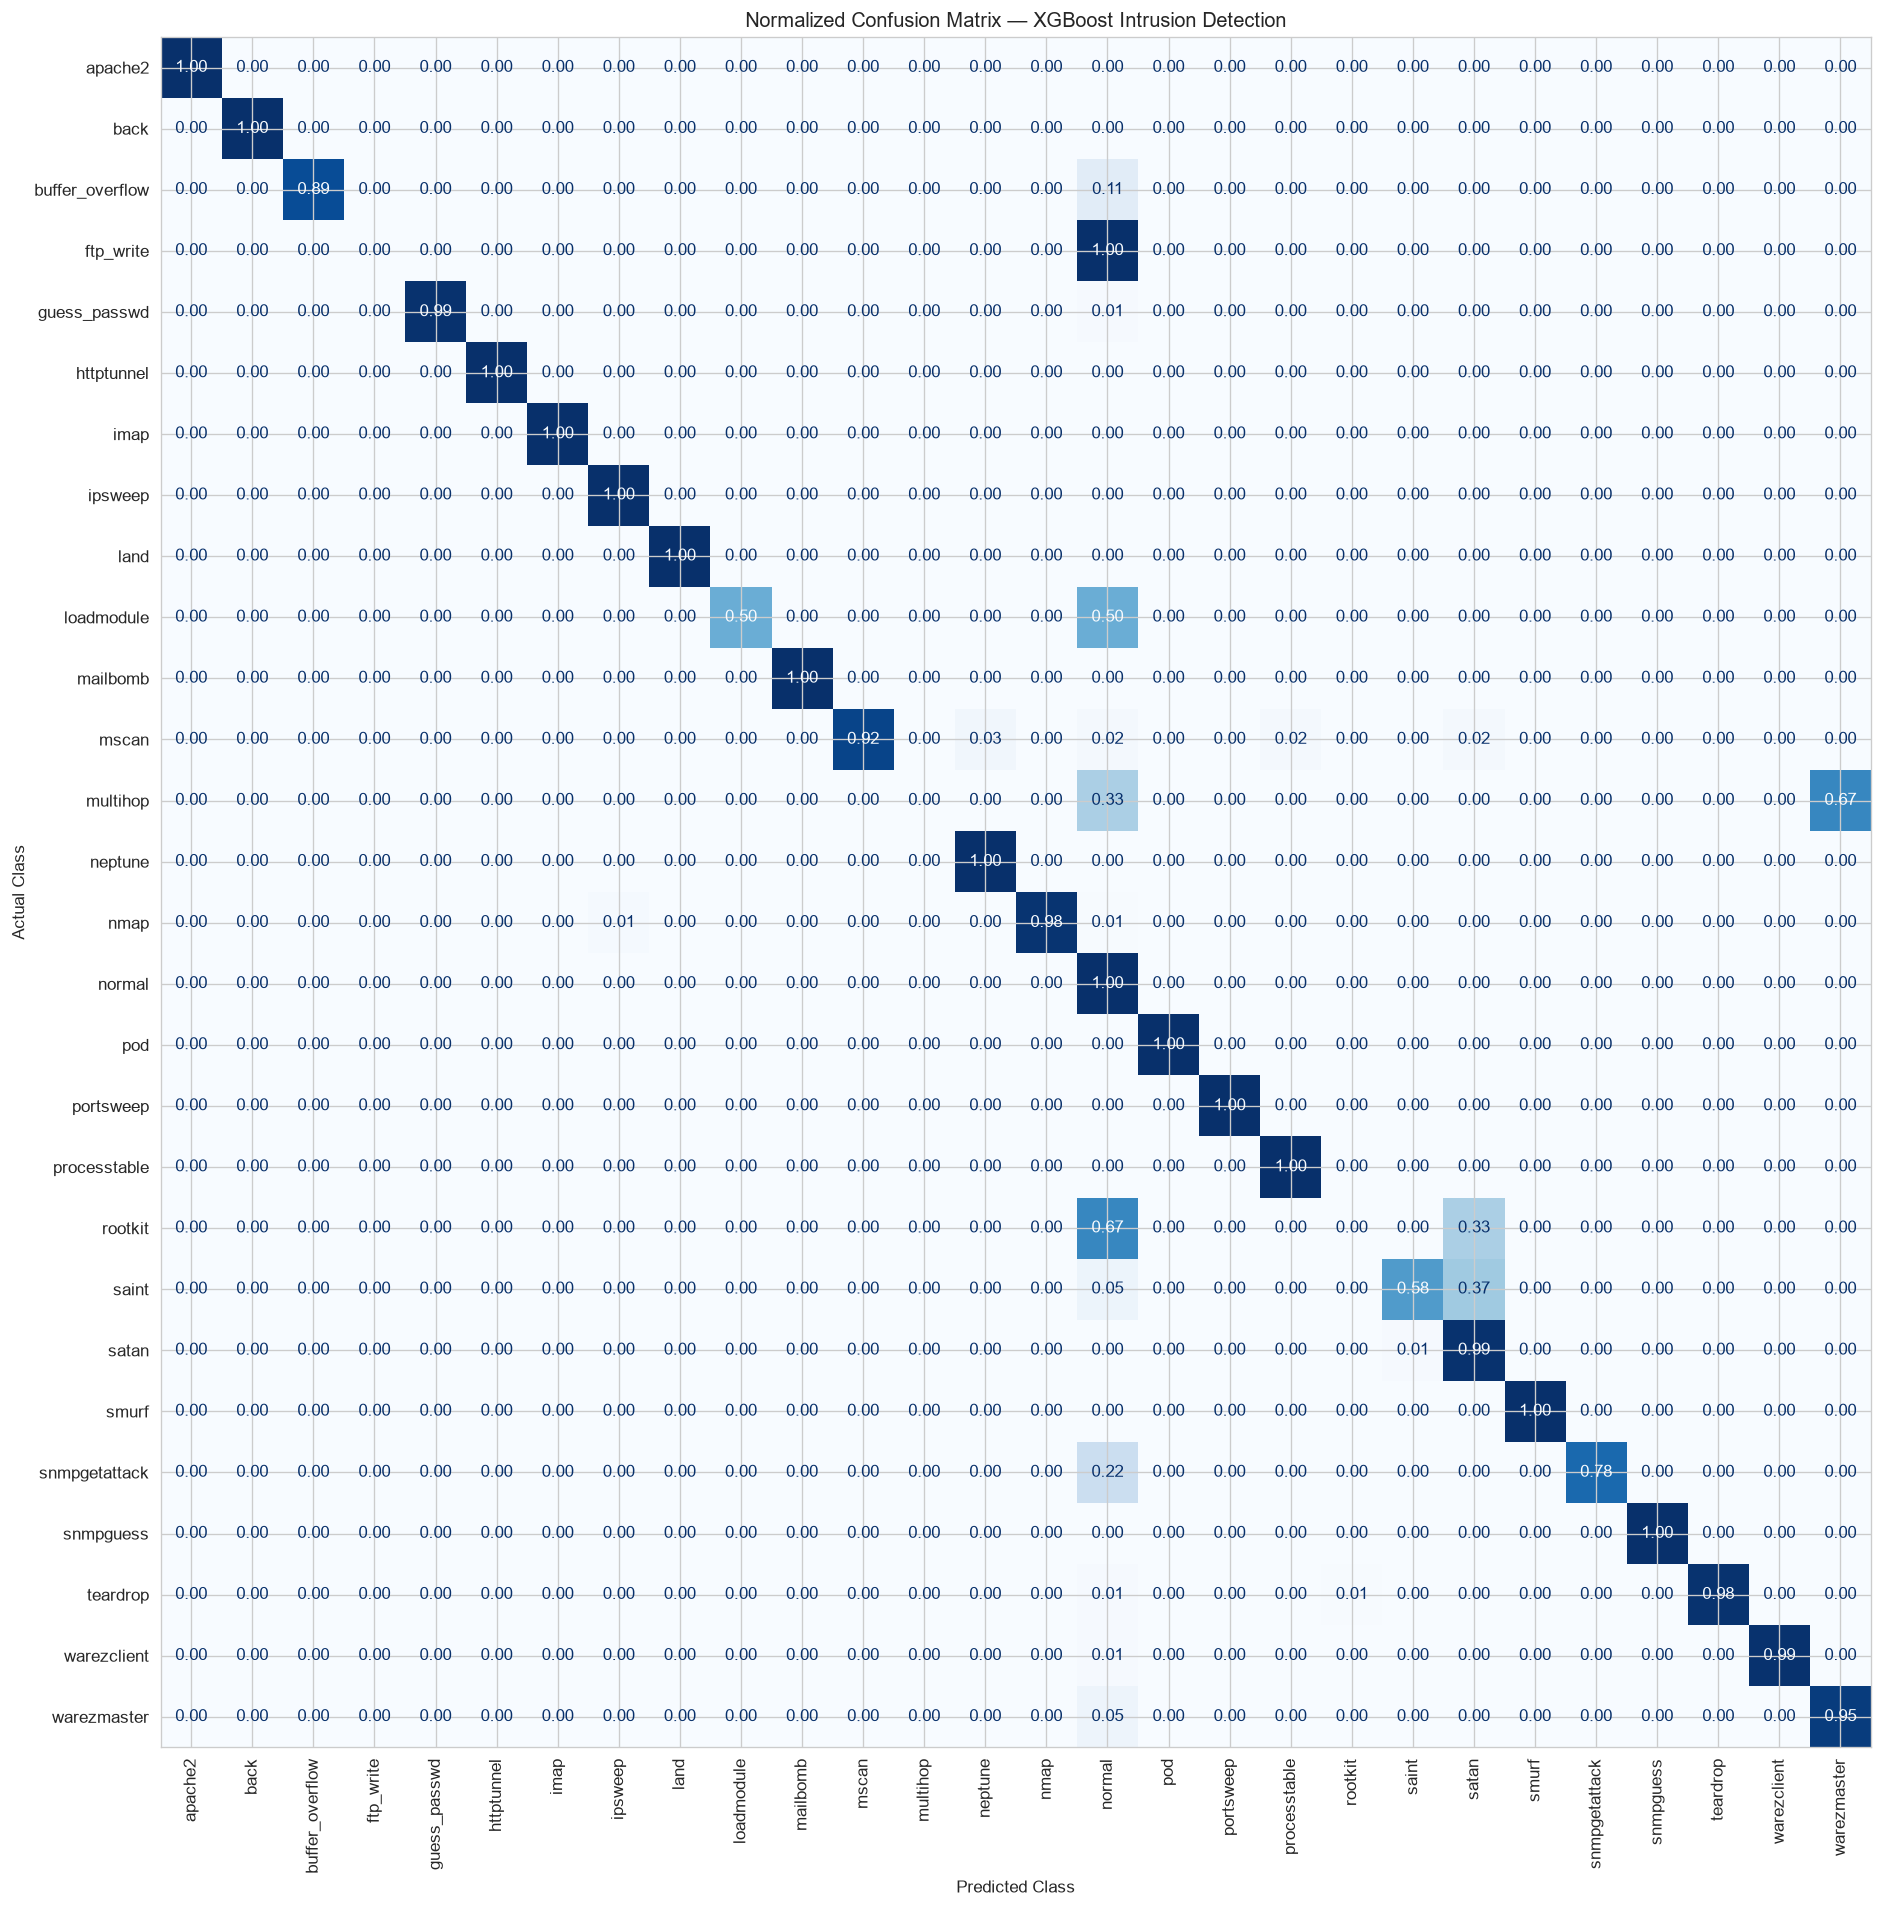

Confusion matrix shape: (28, 28)
Confusion matrix CSV saved: D:\smart-cybersecurity-ml\results\phase5\phase5_confusion_matrix.csv
Confusion matrix plot saved: D:\smart-cybersecurity-ml\results\phase5\phase5_confusion_matrix.png
STEP 5.5.3 COMPLETED SUCCESSFULLY


In [ ]:

# ============================================================
# PHASE 5 — STEP 5.6.2: CONFUSION MATRIX
# ============================================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd

# Use the same label order for actual and predicted classes
class_labels = np.arange(len(class_names))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=class_labels
)

# Save the complete confusion matrix as CSV
cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_csv_path = results_dir / "phase5_confusion_matrix.csv"
cm_df.to_csv(cm_csv_path)

# Plot normalized confusion matrix to compare classes
cm_normalized = confusion_matrix(
    y_true,
    y_pred,
    labels=class_labels,
    normalize="true"
)

fig, ax = plt.subplots(figsize=(18, 16))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=class_names
)

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation="vertical",
    values_format=".2f",
    colorbar=False
)

ax.set_title("Normalized Confusion Matrix — XGBoost Intrusion Detection")
ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

plt.tight_layout()

cm_plot_path = results_dir / "phase5_confusion_matrix.png"
plt.savefig(cm_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Confusion matrix shape:", cm.shape)
print("Confusion matrix CSV saved:", cm_csv_path)
print("Confusion matrix plot saved:", cm_plot_path)
print("STEP 5.5.3 COMPLETED SUCCESSFULLY")


## Step 5.6.3: Misclassified Attack Pattern Analysis

**Objective:** Identify the most frequent actual-to-predicted class errors and export the results for further investigation.

In [ ]:

# ============================================================
# PHASE 5 — STEP 5.6.3: MISCLASSIFIED ATTACK PATTERNS
# ============================================================

# Keep only incorrectly classified records
errors_df = misclassified_df.copy()

if errors_df.empty:
    print("No misclassified records found.")
else:
    # Count actual-to-predicted error pairs
    error_patterns = (
        errors_df.groupby(["Actual_Class", "Predicted_Class"])
        .size()
        .reset_index(name="Count")
        .sort_values("Count", ascending=False)
        .reset_index(drop=True)
    )

    patterns_path = results_dir / "phase5_misclassification_patterns.csv"
    error_patterns.to_csv(patterns_path, index=False)

    print("=" * 65)
    print("TOP MISCLASSIFICATION PATTERNS")
    print("=" * 65)
    print(error_patterns.head(15).to_string(index=False))

    print("\nUnique error patterns:", len(error_patterns))
    print("Misclassification patterns saved:", patterns_path)

    # Count errors by actual class
    errors_by_actual = (
        errors_df.groupby("Actual_Class")
        .size()
        .reset_index(name="Misclassified_Count")
        .sort_values("Misclassified_Count", ascending=False)
        .reset_index(drop=True)
    )

    actual_errors_path = results_dir / "phase5_errors_by_actual_class.csv"
    errors_by_actual.to_csv(actual_errors_path, index=False)

    print("\nERRORS BY ACTUAL CLASS")
    print(errors_by_actual.head(10).to_string(index=False))
    print("Saved:", actual_errors_path)

print("\nSTEP 5.5.4 COMPLETED SUCCESSFULLY")


TOP MISCLASSIFICATION PATTERNS
Actual_Class Predicted_Class  Count
       saint           satan      7
       satan           saint      7
      normal           satan      4
      normal   snmpgetattack      4
        nmap         ipsweep      4
       satan          normal      3
      normal             pod      3
      normal            land      3
 warezmaster          normal      3
    teardrop          normal      2
     rootkit          normal      2
   ftp_write          normal      2
 warezclient          normal      2
       mscan         neptune      2
        nmap          normal      2

Unique error patterns: 36
Misclassification patterns saved: D:\smart-cybersecurity-ml\results\phase5\phase5_misclassification_patterns.csv

ERRORS BY ACTUAL CLASS
Actual_Class  Misclassified_Count
      normal                   18
       satan                   10
       saint                    8
        nmap                    6
       mscan                    5
    teardrop             

## Step 5.6.4: Recover Original Feature Names

**Objective:** Check the available dataset and preprocessing artifacts to identify the original names of the 41 model input features.

In [109]:

# Reload test data if the variable is not currently defined
if "X_test_encoded" not in globals():
    X_test_encoded = pd.read_csv(
        processed_dir / "X_test_encoded.csv"
    )

print("X_train shape:", X_train.shape)
print("X_test_encoded shape:", X_test_encoded.shape)

print("\nColumns in X_test_encoded:")
print(X_test_encoded.columns.tolist())

print("\nSaved preprocessing files:")
for filename in ["scaler.pkl", "target_encoder.pkl"]:
    path = processed_dir / filename
    print(f"{filename}: {'FOUND' if path.exists() else 'NOT FOUND'}")

if hasattr(scaler, "feature_names_in_"):
    print("\nScaler feature names:")
    print(list(scaler.feature_names_in_))
else:
    print("\nScaler does not contain feature_names_in_.")

print("\nSTEP 5.6.2 COMPLETED")


X_train shape: (118783, 41)
X_test_encoded shape: (29696, 41)

Columns in X_test_encoded:
['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']

Saved preprocessing files:
scaler.pkl: FOUND
target_encoder.pkl: FOUND

Scaler feature names:
['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wr

In [ ]:

# ============================================================
# PHASE 5 — STEP 5.6.5: CHECK FEATURE-NAME SOURCES
# ============================================================

print("=" * 65)
print("FEATURE-NAME RECOVERY CHECK")
print("=" * 65)

print("X_train shape:", X_train.shape)
print("X_test_encoded shape:", X_test_encoded.shape)

print("\nColumns in X_test_encoded:")
print(X_test_encoded.columns.tolist())

print("\nSaved preprocessing files:")
for filename in [
    "scaler.pkl",
    "target_encoder.pkl"
]:
    path = processed_dir / filename
    print(f"{filename}: {'FOUND' if path.exists() else 'NOT FOUND'}")

# Check whether the scaler retained feature names
if hasattr(scaler, "feature_names_in_"):
    print("\nScaler feature names:")
    print(list(scaler.feature_names_in_))
else:
    print("\nScaler does not contain feature_names_in_.")

print("\nSTEP 5.6.2 COMPLETED")


FEATURE-NAME RECOVERY CHECK
X_train shape: (118783, 41)
X_test_encoded shape: (29696, 41)

Columns in X_test_encoded:
['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']

Saved preprocessing files:
scaler.pkl: FOUND
target_encoder.pkl: FOUND

Scaler feature names:
['duration', 'protocol_type', 'service', 'flag', 'src_byte

## Step 5.6.6: Map Feature Importance to Original Dataset Columns

**Objective:** Replace generic feature labels with the verified original names of the 41 input columns and save the mapped feature-importance results.

In [ ]:

# ============================================================
# PHASE 5 — STEP 5.6.6: MAP ORIGINAL FEATURE NAMES
# ============================================================

import re

# Preserve the verified order of the 41 input columns
original_feature_names = X_test_encoded.columns.tolist()

assert len(original_feature_names) == X_train.shape[1], (
    "Feature count mismatch: verify preprocessing and model inputs."
)

# Build mappings such as feature_4 -> src_bytes (depending on column order)
feature_name_map = {
    f"feature_{i}": name
    for i, name in enumerate(original_feature_names)
}

def get_original_feature_name(label):
    """Map generic labels like f4 or feature_4 to original column names."""
    label = str(label)

    match = re.fullmatch(r"(?:feature_|f)(\d+)", label)
    if match:
        index = int(match.group(1))
        if 0 <= index < len(original_feature_names):
            return original_feature_names[index]

    return label

# Map the existing gain-importance table
mapped_importance_df = primary_importance.copy()

source_col = (
    "Feature_Name"
    if "Feature_Name" in mapped_importance_df.columns
    else "Feature"
)

mapped_importance_df["Original_Feature"] = (
    mapped_importance_df[source_col].apply(get_original_feature_name)
)

mapped_importance_df = mapped_importance_df.sort_values(
    "Importance", ascending=False
).reset_index(drop=True)

mapped_importance_path = (
    results_dir / "phase5_feature_importance_named.csv"
)
mapped_importance_df.to_csv(mapped_importance_path, index=False)

print("=" * 65)
print("TOP 20 FEATURES WITH ORIGINAL NAMES")
print("=" * 65)
print(
    mapped_importance_df[
        ["Original_Feature", "Importance"]
    ].head(20).to_string(index=False)
)

print("\nSaved:", mapped_importance_path)
print("Verified feature count:", len(original_feature_names))
print("STEP 5.6.3 COMPLETED SUCCESSFULLY")


TOP 20 FEATURES WITH ORIGINAL NAMES
           Original_Feature  Importance
                       land  698.815613
                     urgent  587.063843
              same_srv_rate  465.742889
             wrong_fragment  365.454193
          num_failed_logins  349.490631
                 root_shell  264.051270
                 num_shells  241.546234
            srv_serror_rate  138.501541
                   num_root  124.001602
           num_access_files  112.961617
              protocol_type   99.021538
                  src_bytes   97.633965
              diff_srv_rate   88.581696
                       flag   88.310638
dst_host_srv_diff_host_rate   69.205292
             is_guest_login   53.812222
                   duration   48.689888
                  dst_bytes   38.283066
   dst_host_srv_rerror_rate   37.828346
                        hot   36.680840

Saved: D:\smart-cybersecurity-ml\results\phase5\phase5_feature_importance_named.csv
Verified feature count: 41
STEP 5.6.3 C

## Step 5.6.7: Map LIME Explanation to Original Feature Names

**Objective:** Replace generic feature labels in the saved LIME explanation with the verified original dataset column names.

In [ ]:

# ============================================================
# PHASE 5 — STEP 5.6.7: MAP LIME FEATURE NAMES
# ============================================================

import re
import pandas as pd

def map_lime_condition(condition):
    """
    Convert generic LIME conditions such as
    'feature_4 <= 0.00' into original column names.
    """
    condition = str(condition)

    def replace_feature(match):
        index = int(match.group(1))
        if 0 <= index < len(original_feature_names):
            return original_feature_names[index]
        return match.group(0)

    return re.sub(r"\bfeature_(\d+)\b", replace_feature, condition)

lime_named_df = lime_results_df.copy()

lime_named_df["Original_Feature_Condition"] = (
    lime_named_df["Feature_Condition"].apply(map_lime_condition)
)

lime_named_path = (
    results_dir / "phase5_lime_individual_explanation_named.csv"
)

lime_named_df.to_csv(lime_named_path, index=False)

print("=" * 65)
print("LIME EXPLANATION WITH ORIGINAL FEATURE NAMES")
print("=" * 65)

print(
    lime_named_df[
        ["Original_Feature_Condition", "LIME_Weight"]
    ].to_string(index=False)
)

print("\nSaved:", lime_named_path)
print("STEP 5.6.4 COMPLETED SUCCESSFULLY")


LIME EXPLANATION WITH ORIGINAL FEATURE NAMES
      Original_Feature_Condition  LIME_Weight
               src_bytes <= 0.00     0.255613
                     hot <= 0.00     0.154305
                logged_in > 1.00     0.125781
   dst_host_same_srv_rate > 1.00     0.125781
                num_root <= 0.00     0.109734
         num_compromised <= 0.00     0.090432
dst_host_srv_serror_rate <= 0.00     0.068373
             rerror_rate <= 0.00     0.061209
                duration <= 0.00    -0.059612
              root_shell <= 0.00    -0.046647
         srv_rerror_rate <= 0.00     0.045409
     dst_host_srv_count <= 11.00     0.033917
    dst_host_serror_rate <= 0.00    -0.030056
    0.10 < same_srv_rate <= 1.00     0.018620
      num_file_creations <= 0.00    -0.012373

Saved: D:\smart-cybersecurity-ml\results\phase5\phase5_lime_individual_explanation_named.csv
STEP 5.6.4 COMPLETED SUCCESSFULLY


## Step 5.7: Final Results Summary and Artifact Verification

**Objective:** Verify the Phase 5 output files and prepare a summary of model performance, explainability results, and attack-class analysis.

In [113]:


# ============================================================
# PHASE 5 — STEP 5.7.2: VERIFY PHASE 5 ARTIFACTS
# ============================================================

expected_files = [
    "phase5_feature_importance.csv",
    "phase5_feature_importance_named.csv",
    "phase5_feature_importance_weight.csv",
    "phase5_feature_importance_gain.csv",
    "phase5_feature_importance_cover.csv",
    "phase5_feature_importance_total_gain.csv",
    "phase5_feature_importance_top20.png",
    "phase5_lime_individual_explanation.png",
    "phase5_lime_individual_explanation.csv",
    "phase5_lime_individual_explanation_named.csv",
    "phase5_attack_class_analysis.csv",
    "phase5_misclassified_records.csv",
    "phase5_confusion_matrix.csv",
    "phase5_confusion_matrix.png",
    "phase5_misclassification_patterns.csv",
    "phase5_errors_by_actual_class.csv",
]

print("=" * 70)
print("PHASE 5 — ARTIFACT VERIFICATION")
print("=" * 70)

verification_rows = []

for filename in expected_files:
    file_path = results_dir / filename
    exists = file_path.exists()

    verification_rows.append({
        "File": filename,
        "Status": "FOUND" if exists else "MISSING",
        "Size_KB": round(file_path.stat().st_size / 1024, 2)
        if exists else None
    })

verification_df = pd.DataFrame(verification_rows)

print(verification_df.to_string(index=False))

found_count = sum(
    row["Status"] == "FOUND" for row in verification_rows
)
missing_count = len(expected_files) - found_count

print("\nTotal expected files:", len(expected_files))
print("Files found:", found_count)
print("Files missing:", missing_count)
print("Results directory:", results_dir)

verification_path = results_dir / "phase5_artifact_verification.csv"
verification_df.to_csv(verification_path, index=False)

print("Verification report saved:", verification_path)
print("\nSTEP 5.7.2 COMPLETED")


PHASE 5 — ARTIFACT VERIFICATION
                                        File Status  Size_KB
               phase5_feature_importance.csv  FOUND     1.08
         phase5_feature_importance_named.csv  FOUND     1.69
        phase5_feature_importance_weight.csv  FOUND     0.62
          phase5_feature_importance_gain.csv  FOUND     1.08
         phase5_feature_importance_cover.csv  FOUND     1.06
    phase5_feature_importance_total_gain.csv  FOUND     0.95
         phase5_feature_importance_top20.png  FOUND   105.14
      phase5_lime_individual_explanation.png  FOUND   115.25
      phase5_lime_individual_explanation.csv  FOUND     1.20
phase5_lime_individual_explanation_named.csv  FOUND     1.56
            phase5_attack_class_analysis.csv  FOUND     1.32
            phase5_misclassified_records.csv  FOUND     1.58
                 phase5_confusion_matrix.csv  FOUND     2.07
                 phase5_confusion_matrix.png  FOUND  1331.95
       phase5_misclassification_patterns.csv  FOUND  

### Step 5.7.3: Final Model Results Summary

**Objective:** Summarize model performance, attack-class weaknesses, misclassification patterns, and explainability outputs for the final project report.

**Important note:** SHAP could not be initialized because Windows blocked a native dependency. LIME and the other Phase 5 analyses were completed successfully.

In [114]:

# ============================================================
# PHASE 5 — STEP 5.7.4: FINAL ANALYSIS SUMMARY
# ============================================================

from pathlib import Path
import pandas as pd

# STEP 1: Set the CORRECT Phase 5 results directory
results_dir = Path(
    r"D:\smart-cybersecurity-ml\results\phase5"
)

if not results_dir.exists():
    raise FileNotFoundError(
        f"Phase 5 results directory not found: {results_dir}"
    )

# STEP 2: Load existing Phase 5 output files safely
required_files = {
    "attack_class": "phase5_attack_class_analysis.csv",
    "errors": "phase5_misclassified_records.csv",
    "patterns": "phase5_misclassification_patterns.csv",
    "importance": "phase5_feature_importance_named.csv",
    "lime": "phase5_lime_individual_explanation_named.csv",
}

loaded_data = {}

for key, filename in required_files.items():
    file_path = results_dir / filename

    if not file_path.exists():
        raise FileNotFoundError(
            f"Required file missing: {file_path}"
        )

    loaded_data[key] = pd.read_csv(file_path)

class_df = loaded_data["attack_class"]
errors_df = loaded_data["errors"]
patterns_df = loaded_data["patterns"]
importance_df = loaded_data["importance"]
lime_df = loaded_data["lime"]

# STEP 3: Print final summary
print("=" * 70)
print("PHASE 5 — FINAL ANALYSIS SUMMARY")
print("=" * 70)

print("\n1. ATTACK-CLASS ANALYSIS")
print("Classes analyzed:", len(class_df))

# Find the actual F1 column regardless of capitalization
f1_candidates = [
    col for col in class_df.columns
    if col.strip().lower() in ["f1", "f1-score", "f1_score", "f1 score"]
]

if f1_candidates:
    f1_col = f1_candidates[0]

    print("\n10 classes with the lowest F1 scores:")
    print(
        class_df.sort_values(f1_col, ascending=True)
        .head(10)
        .to_string(index=False)
    )
else:
    print("F1 column not found.")
    print("Available columns:", class_df.columns.tolist())

print("\n2. MISCLASSIFICATION ANALYSIS")
print("Misclassified records:", len(errors_df))
print("Unique error patterns:", len(patterns_df))

print("\n3. TOP 10 FEATURES")

# Prefer original feature names if available
feature_col = (
    "Original_Feature"
    if "Original_Feature" in importance_df.columns
    else "Feature_Name"
    if "Feature_Name" in importance_df.columns
    else "Feature"
    if "Feature" in importance_df.columns
    else None
)

if "Importance" in importance_df.columns and feature_col:
    top_features = importance_df.sort_values(
        "Importance", ascending=False
    ).head(10)

    print(top_features[[feature_col, "Importance"]].to_string(index=False))
else:
    print("Feature columns:", importance_df.columns.tolist())
    print(importance_df.head(10).to_string(index=False))

print("\n4. LIME LOCAL EXPLANATION")
print(lime_df.head(10).to_string(index=False))

print("\n5. EXPLAINABILITY STATUS")
print("Feature importance: Completed")
print("LIME local explanation: Completed")
print("SHAP: Blocked by Windows Application Control policy")

# STEP 4: Save a concise summary report
summary = pd.DataFrame([
    {"Item": "Attack classes analyzed", "Result": len(class_df)},
    {"Item": "Misclassified records", "Result": len(errors_df)},
    {"Item": "Unique error patterns", "Result": len(patterns_df)},
    {"Item": "Feature importance", "Result": "Completed"},
    {"Item": "LIME explanation", "Result": "Completed"},
    {"Item": "SHAP", "Result": "Blocked by Windows security policy"},
])

summary_path = results_dir / "phase5_final_summary.csv"
summary.to_csv(summary_path, index=False)

print("\nFinal summary saved to:", summary_path)
print("\nSTEP 5.7.4 COMPLETED SUCCESSFULLY")


PHASE 5 — FINAL ANALYSIS SUMMARY

1. ATTACK-CLASS ANALYSIS
Classes analyzed: 28

10 classes with the lowest F1 scores:
         Attack  Precision   Recall       F1  Support
      ftp_write   0.000000 0.000000 0.000000        2
       multihop   0.000000 0.000000 0.000000        3
        rootkit   0.000000 0.000000 0.000000        3
          saint   0.611111 0.578947 0.594595       19
     loadmodule   1.000000 0.500000 0.666667        2
  snmpgetattack   0.636364 0.777778 0.700000        9
           land   0.571429 1.000000 0.727273        4
buffer_overflow   1.000000 0.888889 0.941176        9
    warezmaster   0.950000 0.950000 0.950000       60
          mscan   0.982759 0.919355 0.950000       62

2. MISCLASSIFICATION ANALYSIS
Misclassified records: 73
Unique error patterns: 36

3. TOP 10 FEATURES
 Original_Feature  Importance
             land  698.815613
           urgent  587.063843
    same_srv_rate  465.742889
   wrong_fragment  365.454193
num_failed_logins  349.490631
    

In [115]:

from pathlib import Path

project_root = Path(r"D:\smart-cybersecurity-ml")

important_files = [
    "models/final_xgboost_model.pkl",
    "data/processed/scaler.pkl",
    "data/processed/target_encoder.pkl",
    "data/processed/X_test_encoded.csv",
    "data/processed/y_test_encoded.npy",
]

print("=" * 65)
print("FINAL MODEL AND PREPROCESSING FILE CHECK")
print("=" * 65)

for relative_path in important_files:
    path = project_root / relative_path

    if path.exists():
        print(f"[FOUND]   {relative_path} ({path.stat().st_size:,} bytes)")
    else:
        print(f"[MISSING] {relative_path}")

print("\nVerification complete.")


FINAL MODEL AND PREPROCESSING FILE CHECK
[FOUND]   models/final_xgboost_model.pkl (7,063,074 bytes)
[FOUND]   data/processed/scaler.pkl (2,479 bytes)
[FOUND]   data/processed/target_encoder.pkl (775 bytes)
[FOUND]   data/processed/X_test_encoded.csv (3,670,090 bytes)
[FOUND]   data/processed/y_test_encoded.npy (237,696 bytes)

Verification complete.



# PHASE 5 — STEP 1: DIAGNOSE SAVED ARTIFACTS
only for checking

In [118]:

# PHASE 5 — STEP 1: DIAGNOSE SAVED ARTIFACTS

from pathlib import Path
import sys
import pickle
import joblib

BASE_DIR = Path(r"D:\smart-cybersecurity-ml")

artifact_paths = {
    "model": BASE_DIR / "models" / "final_xgboost_model.pkl",
    "scaler": BASE_DIR / "data" / "processed" / "scaler.pkl",
    "encoder": BASE_DIR / "data" / "processed" / "target_encoder.pkl",
}

print("Python:", sys.version)
print("Python executable:", sys.executable)
print("Pickle protocol supported:", pickle.HIGHEST_PROTOCOL)
print("Joblib version:", joblib.__version__)

for name, path in artifact_paths.items():
    print(f"\n--- {name.upper()} ---")
    print("Path exists:", path.exists())

    if not path.exists():
        continue

    with open(path, "rb") as f:
        header = f.read(16)

    print("File size:", path.stat().st_size)
    print("First 16 bytes:", repr(header))

    # Try standard pickle loading without modifying the file
    try:
        with open(path, "rb") as f:
            obj = pickle.load(f)
        print("pickle.load: SUCCESS")
        print("Object type:", type(obj))
    except Exception as e:
        print("pickle.load:", type(e).__name__, str(e))

    # Try joblib loading separately
    try:
        obj = joblib.load(path)
        print("joblib.load: SUCCESS")
        print("Object type:", type(obj))
    except Exception as e:
        print("joblib.load:", type(e).__name__, str(e))


Python: 3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]
Python executable: d:\smart-cybersecurity-ml\.venv\Scripts\python.exe
Pickle protocol supported: 5
Joblib version: 1.6.0

--- MODEL ---
Path exists: True
File size: 7063074
First 16 bytes: b'\x80\x04\x95\x7f\x03\x00\x00\x00\x00\x00\x00\x8c\x0fxgb'
pickle.load: SUCCESS
Object type: <class 'xgboost.sklearn.XGBClassifier'>
joblib.load: SUCCESS
Object type: <class 'xgboost.sklearn.XGBClassifier'>

--- SCALER ---
Path exists: True
File size: 2479
First 16 bytes: b'\x80\x04\x95=\x01\x00\x00\x00\x00\x00\x00\x8c\x1bskl'
pickle.load: UnpicklingError STACK_GLOBAL requires str
joblib.load: SUCCESS
Object type: <class 'sklearn.preprocessing._data.StandardScaler'>

--- ENCODER ---
Path exists: True
File size: 775
First 16 bytes: b'\x80\x04\x95\x12\x01\x00\x00\x00\x00\x00\x00\x8c\x1cskl'
pickle.load: UnpicklingError STACK_GLOBAL requires str
joblib.load: SUCCESS
Object type: <class 'sklearn.preprocessing._label.

Generate report

In [1]:

# ============================================================
# PHASE 5 — AUTOMATIC XAI REPORT GENERATION
# ============================================================

from pathlib import Path
from datetime import datetime
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
RESULTS_DIR = PROJECT_ROOT / "results" / "phase5"
REPORTS_DIR = PROJECT_ROOT / "reports" / "phase5"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

report_path = REPORTS_DIR / "phase5_explainable_ai_report.txt"

lines = [
    "=" * 80,
    "PHASE 5 — EXPLAINABLE AI (XAI) REPORT",
    "=" * 80,
    "",
    "PROJECT: Smart Cybersecurity Using Machine Learning",
    "PURPOSE: Intrusion Detection and Threat Prevention",
    f"Generated on: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}",
    "",
    "1. PHASE OVERVIEW",
    "-" * 80,
    "This report summarizes the saved outputs from Phase 5, including",
    "model evaluation, feature importance, SHAP, LIME, and error analysis.",
    "",
]

# Read actual CSV outputs instead of inventing values
csv_files = sorted(RESULTS_DIR.glob("*.csv"))

lines += [
    "2. GENERATED CSV RESULTS",
    "-" * 80,
]

if csv_files:
    for file in csv_files:
        lines.append(f"\nFile: {file.name}")
        try:
            df = pd.read_csv(file)
            lines.append(f"Rows: {len(df)}")
            lines.append(f"Columns: {len(df.columns)}")
            lines.append("Column names: " + ", ".join(map(str, df.columns)))
            lines.append("Preview:")
            lines.extend(df.head(5).to_string(index=False).splitlines())
        except Exception as exc:
            lines.append(f"Could not read file: {exc}")
else:
    lines.append("No CSV result files were found.")

lines += [
    "",
    "3. GENERATED VISUALIZATIONS AND OTHER ARTIFACTS",
    "-" * 80,
]

artifacts = sorted(
    p for p in RESULTS_DIR.iterdir()
    if p.is_file()
)

if artifacts:
    for file in artifacts:
        lines.append(f"{file.name} ({file.stat().st_size:,} bytes)")
else:
    lines.append("No result artifacts were found.")

lines += [
    "",
    "4. ARTIFACT SUMMARY",
    "-" * 80,
    f"CSV files found: {len(csv_files)}",
    f"Total files found: {len(artifacts)}",
    "",
    "5. CONCLUSION",
    "-" * 80,
    "This report was generated automatically from the Phase 5 results folder.",
    "The CSV previews and artifact list reflect files available at generation time.",
    "For updated metrics, rerun the Phase 5 analysis cells before generating",
    "this report again.",
    "",
    "=" * 80,
    "END OF PHASE 5 REPORT",
    "=" * 80,
]

report_path.write_text("\n".join(lines), encoding="utf-8")

print("PHASE 5 REPORT GENERATED SUCCESSFULLY")
print(f"Report location: {report_path}")
print(f"CSV files included: {len(csv_files)}")
print(f"Artifacts found: {len(artifacts)}")


PHASE 5 REPORT GENERATED SUCCESSFULLY
Report location: d:\smart-cybersecurity-ml\reports\phase5\phase5_explainable_ai_report.txt
CSV files included: 18
Artifacts found: 22
